# 1. Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Setup

In [12]:

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/raw/student_dropout_risk_2026.csv")

print(f"Dataset shape: {df.shape}")
print(f"Number of observations: {df.shape[0]:,}")
print(f"Number of features: {df.shape[1]}")

df.head()

Dataset shape: (100000, 34)
Number of observations: 100,000
Number of features: 34


,person_id,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,weekly_work_hours,course_type,study_mode,semester,international_student,admission_grade,previous_qualification_grade,units_enrolled,units_passed,units_failed,gpa_semester_1,gpa_semester_2,attendance_rate,assignments_submitted_rate,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
0,1,23,Male,Brazil,0,0,Low,1,0,1,24,STEM,Online,7,0,164.6,165.1,11,11,0,3.44,2.55,77.3,75.0,4,16.3,0,3,8,0,6,37,5.7,0
1,2,18,Other,USA,1,1,High,1,1,0,0,Arts & Humanities,Full-time,6,1,175.2,164.1,14,11,3,2.56,2.53,52.1,80.1,3,8.4,1,1,7,0,6,15,5.4,1
2,3,24,Other,USA,0,0,High,0,1,1,16,Arts & Humanities,Full-time,3,0,126.0,179.3,17,14,3,3.43,2.73,100.0,67.8,3,11.3,1,0,2,0,3,4,4.3,0
3,4,25,Female,USA,0,1,Middle,1,1,0,0,Business,Full-time,1,0,75.5,161.9,13,11,2,2.51,2.10,83.9,100.0,2,13.2,1,1,5,0,7,10,6.7,0
4,5,15,Female,Canada,0,0,Low,1,1,0,0,Health Sciences,Part-time,2,0,89.0,101.8,8,7,1,3.93,2.88,61.6,100.0,4,7.4,1,0,7,0,10,24,5.8,0


# 3. General structure of dataset

The dataset contains 100,000 observations and 34 columns, including student-related demographic, academic, financial, and behavioral variables.

The initial inspection reveals the following:

- No missing values were detected.

- No duplicated rows or duplicated student IDs were found.

- The dataset contains numerical and categorical variables.

- Although the dataset appears complete from a structural perspective, further validation is required to identify potentially implausible values and inconsistencies.

The absence of missing values and duplicates does not necessarily guarantee data quality. Additional checks are needed to assess the validity of the observations.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 34 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   person_id                     100000 non-null  int64  
 1   age                           100000 non-null  int64  
 2   gender                        100000 non-null  str    
 3   nationality                   100000 non-null  str    
 4   first_generation              100000 non-null  int64  
 5   disability_status             100000 non-null  int64  
 6   family_income_level           100000 non-null  str    
 7   scholarship_holder            100000 non-null  int64  
 8   tuition_up_to_date            100000 non-null  int64  
 9   part_time_job                 100000 non-null  int64  
 10  weekly_work_hours             100000 non-null  int64  
 11  course_type                   100000 non-null  str    
 12  study_mode                    100000 non-null  str    
 

As we saw previously, we have no missing values and no duplicated values

In [13]:

print("Missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated student IDs:", df["person_id"].duplicated().sum())

Missing values: 0
Duplicated rows: 0
Duplicated student IDs: 0


The target variable, dropout, is distributed as follows:

- Approximately 68% of students did not drop out.

- Approximately 32% of students dropped out.

The dataset presents a moderate class imbalance, with non-dropout cases being more frequent than dropout cases. Although this imbalance is not extreme, it should be considered when evaluating future classification models.

In particular, accuracy alone may not be sufficient to assess model performance. Metrics such as precision, recall, F1-score, and ROC-AUC should also be considered.

In [5]:
print(df["dropout"].value_counts())
print()
print(df["dropout"].value_counts(normalize=True).round(3))

dropout
0    67996
1    32004
Name: count, dtype: int64

dropout
0    0.68
1    0.32
Name: proportion, dtype: float64


We can see several insights
- <b>Age</b>: the mean age is approximately 21.52 years, with values ranging from 15 to 30.

- <b>Academic performance</b>: the mean GPA decreases from 2.57 in semester 1 to 1.98 in semester 2. This difference deserves further investigation, although aggregate statistics alone do not establish why it occurs.

- <b>Admission grade</b>: the mean is approximately 133.15, while the minimum is 5.5. The minimum value should be investigated to determine whether it represents a valid observation or a potential data-quality issue.

These statistics provide an initial overview of the dataset. Distribution plots and further validation checks are needed before drawing stronger conclusions.

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
person_id,100000.0,50000.500000,28867.657797,1.0,25000.75,50000.50,75000.25,100000.0
age,100000.0,21.520840,3.399468,15.0,19.00,21.00,24.00,30.0
first_generation,100000.0,0.420130,0.493582,0.0,0.00,0.00,1.00,1.0
disability_status,100000.0,0.208770,0.406432,0.0,0.00,0.00,0.00,1.0
scholarship_holder,100000.0,0.589700,0.491891,0.0,0.00,1.00,1.00,1.0
tuition_up_to_date,100000.0,0.784860,0.410921,0.0,1.00,1.00,1.00,1.0
part_time_job,100000.0,0.481920,0.499676,0.0,0.00,0.00,1.00,1.0
weekly_work_hours,100000.0,8.744620,10.232842,0.0,0.00,0.00,18.00,40.0
semester,100000.0,3.617970,2.112763,1.0,2.00,3.00,5.00,8.0
international_student,100000.0,0.180940,0.384970,0.0,0.00,0.00,0.00,1.0


we can see the categorical features

In [7]:
cat_cols = df.select_dtypes(exclude="number").columns
for col in cat_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts().head(10))
    print()

--- gender ---
gender
Female    50731
Male      47224
Other      2045
Name: count, dtype: int64

--- nationality ---
nationality
USA            29979
India          11994
China          10013
Brazil          6873
Mexico          6149
UK              6050
Nigeria         5921
Germany         4072
South Korea     4060
Philippines     3956
Name: count, dtype: int64

--- family_income_level ---
family_income_level
Middle    40213
Low       34809
High      24978
Name: count, dtype: int64

--- course_type ---
course_type
STEM                     30141
Business                 24986
Arts & Humanities        18024
Health Sciences          14941
Law & Social Sciences    11908
Name: count, dtype: int64

--- study_mode ---
study_mode
Full-time    65096
Part-time    21975
Online       12929
Name: count, dtype: int64



The validation checks reveal two relevant findings:

- Age: 7,753 students are younger than 17. Given the apparent higher-education context, these observations deserve further investigation. However, age alone is not sufficient to conclude that the records are invalid or that the dataset is synthetic.

- Academic units: no observations were found in which the sum of passed and failed units exceeds the number of enrolled units.

These checks identify a potential area for further validation while confirming that the tested academic-unit constraint is satisfied across all observations.

Additional domain-specific checks should be performed before deciding whether any observations require correction or removal.

In [8]:
print("Students under 17y/o:", (df["age"] < 17).sum())
print("Units passed + Units failed > Units enrolled:",
      ((df["units_passed"] + df["units_failed"]) > df["units_enrolled"]).sum())

Students under 17y/o: 7753
Units passed + Units failed > Units enrolled: 0


# 4. Exploratory Data Analysis (EDA)

Family income level shows one of the clearest differences in observed dropout rates:

- Low-income students: 42.9% dropout rate.

- Middle-income students: 30.0% dropout rate.

- High-income students: 20.0% dropout rate.

The observed dropout rate is substantially higher among students in the low-income category than among those in the high-income category. The difference between these groups is 22.9 percentage points.

This pattern suggests that family income level may be an important variable to investigate further when studying student dropout risk.

However, these are descriptive, unadjusted comparisons. Further analysis is needed to determine whether the association remains after accounting for other relevant variables.

In [9]:
for col in cat_cols:
    print(f"--- {col} ---")
    print(df.groupby(col)["dropout"].agg(rate="mean", n="size").round(3).sort_values("rate", ascending=False))
    print()

--- gender ---
         rate      n
gender              
Other   0.334   2045
Male    0.320  47224
Female  0.319  50731

--- nationality ---
              rate      n
nationality              
Indonesia    0.330   2982
Germany      0.326   4072
China        0.325  10013
Pakistan     0.324   3030
Australia    0.322    969
India        0.322  11994
UK           0.321   6050
USA          0.320  29979
South Korea  0.319   4060
Brazil       0.318   6873
Nigeria      0.318   5921
Philippines  0.318   3956
Mexico       0.314   6149
Egypt        0.313   1985
Canada       0.301   1967

--- family_income_level ---
                      rate      n
family_income_level              
Low                  0.429  34809
Middle               0.300  40213
High                 0.200  24978

--- course_type ---
                        rate      n
course_type                        
Arts & Humanities      0.321  18024
Health Sciences        0.321  14941
STEM                   0.321  30141
Business         

Several binary variables show noticeable differences in observed dropout rates:
- ```first_generation```: this could be an interesting fact, the first generation has a higher dropout rate (37.4% for first-generation students vs 28.1% for the rest)
- ```disability_status```: we can see that students who have a disability have a higher dropout rate (36.5% for disabled students vs 30.8% for the rest)
- ```tuition_up_to_date```: one of the most relevant features. Students without up-to-date tuition have a higher dropout rate (44.2% vs. 28.7% for students who are up to date).
- ```part_time_job```: students who have a part-time job are more prone to dropout (39.8% for students who have a job vs 24.7% for the rest)
  
These descriptive differences make tuition status, employment, and first-generation status particularly interesting candidates for further investigation.
By contrast, scholarship holders show a slightly lower dropout rate (31.1% versus 33.2%), while international status shows virtually no difference (32.1% versus 32.0%).
These findings describe associations in the observed data and should not be interpreted as evidence of causation.

In [10]:
bin_cols = ["first_generation", "disability_status", "scholarship_holder",
            "tuition_up_to_date", "part_time_job", "international_student"]

for col in bin_cols:
    print(f"--- {col} ---")
    print(df.groupby(col)["dropout"].mean().round(3))
    print()

--- first_generation ---
first_generation
0    0.281
1    0.374
Name: dropout, dtype: float64

--- disability_status ---
disability_status
0    0.308
1    0.365
Name: dropout, dtype: float64

--- scholarship_holder ---
scholarship_holder
0    0.332
1    0.311
Name: dropout, dtype: float64

--- tuition_up_to_date ---
tuition_up_to_date
0    0.442
1    0.287
Name: dropout, dtype: float64

--- part_time_job ---
part_time_job
0    0.247
1    0.398
Name: dropout, dtype: float64

--- international_student ---
international_student
0    0.320
1    0.321
Name: dropout, dtype: float64



Some categorical variables show comparatively small differences in dropout rates:

- Gender: dropout rates are approximately 31.9% for female students, 32.0% for male students, and 33.4% for students identifying as Other.

- Nationality: observed dropout rates range from 30.1% for Canadian students to 33.0% for Indonesian students.

- Course type: dropout rates are very similar across the five course categories, ranging from 31.7% to 32.1%.

- International status: the dropout rate is approximately 32.1% for international students and 32.0% for non-international students.

- Study mode: online students have the lowest observed dropout rate (29.2%), while part-time students have the highest (33.7%).

- Scholarship status: scholarship holders show a slightly lower dropout rate than non-holders (31.1% versus 33.2%).

Overall, course type and international status show very small differences in these unadjusted comparisons. Gender and nationality also show relatively modest differences, although the observed rates vary across categories.

These descriptive results do not establish statistical significance or rule out relationships that may emerge after accounting for other variables.

<br>

Attendance rate shows a clear negative descriptive association with student dropout.

The observed dropout rate decreases across attendance categories, from approximately 59.2% among students with attendance of 50% or less to 16.1% among students with attendance above 90%.

This represents a difference of 43.1 percentage points between the two groups.

The pattern suggests that attendance may be a useful variable for identifying students who could benefit from additional academic support. However, this analysis is descriptive and does not establish a causal relationship. Further investigation is needed to determine whether the association remains after accounting for other student characteristics.

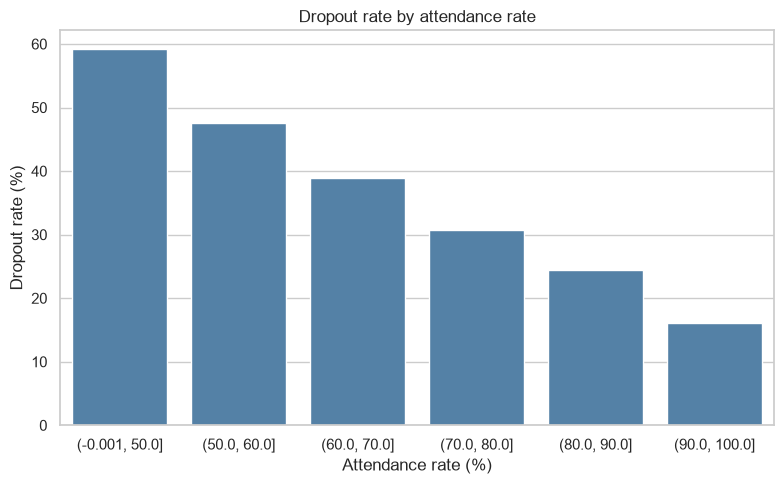

In [11]:
df["attendance_bin"] = pd.cut(df["attendance_rate"], bins=[0, 50, 60, 70, 80, 90, 100], include_lowest=True)
rate = df.groupby("attendance_bin", observed=True)["dropout"].mean() * 100

plt.figure(figsize=(8, 5))
sns.barplot(x=rate.index.astype(str), y=rate.values, color="steelblue")
plt.title("Dropout rate by attendance rate")
plt.xlabel("Attendance rate (%)")
plt.ylabel("Dropout rate (%)")
plt.tight_layout()
plt.savefig("../reports/figures/dropout_by_attendance.png", dpi=150)
plt.show()